# Compass IoT Observed Ranges

## Phase 1 · Rank candidate intersections

The bundled arm inventory matches [Atlanta's signal inventory](https://dpwgis.atlantaga.gov/hostingserver/rest/services/Signalized_Intersections/FeatureServer/0) to [OpenStreetMap](https://www.openstreetmap.org/copyright) road junctions in the Compass study polygon. It uses the closest mapped road junction within 40 m and retains junctions with exactly four road arms. Lane and direction fields reflect OSM tags. Missing turn-lane tags leave the site eligible for review.

1. Exclude sites with a mapped dedicated turn lane or any one-way arm.
2. Rank by the total number of known extra lanes, ascending, then by the number of arms with unresolved lane counts, ascending. Four 1-in/1-out arms rank first. An unresolved arm ranks ahead of a known extra lane. A two-way arm tagged as two total lanes implies one lane per direction.
3. Break ties by distinct Compass vehicles observed within 100 m, descending. This is a coverage check using Point Report positions, including nearby vehicles whose paths may bypass the intersection.

Set `MAX_POINT_FILES = None` to use all compressed Point Report shards. A smaller value previews the first shards. Inspect lane markings before using the shortlisted sites for subsequent analysis.

The table shows the top 20 sites. Ranks 1, 3, 4, 6, and 7 are stored in `analysis_sites` for follow-up analysis.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

DATA_PATH = Path('data/raw/Atlanta_compass_aug2026')
MAX_POINT_FILES = None
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / DATA_PATH).is_dir()), None)
if root is None:
    raise FileNotFoundError('Run from inside the repository with the Atlanta Point Report available.')

arms = pd.read_csv(root / 'notebooks/phase1/atlanta_intersection_arms.csv')
arms['unresolved'] = arms[['inbound_lanes', 'outbound_lanes']].isna().any(axis=1)
directional_extras = (arms[['inbound_lanes', 'outbound_lanes']] - 1).clip(lower=0).sum(axis=1)
arms['extra_lanes'] = np.maximum(directional_extras, (arms['total_lanes'] - 2).clip(lower=0).fillna(0))

sites = arms.groupby(['osm_node', 'intersection', 'latitude', 'longitude'], as_index=False).agg(
    arms=('osm_way', 'size'),
    dedicated_turn_lane=('dedicated_turn_lane', 'any'),
    all_two_way=('two_way', 'all'),
    extra_lanes=('extra_lanes', 'sum'),
    unresolved_arms=('unresolved', 'sum'),
)
four_arm = sites.loc[sites['arms'].eq(4)]
without_turn_lanes = four_arm.loc[~four_arm['dedicated_turn_lane']]
eligible = without_turn_lanes.loc[without_turn_lanes['all_two_way']].copy()
print(f'Four arms: {len(four_arm)}; without mapped turn lanes: {len(without_turn_lanes)}; '
      f'all arms two-way: {len(eligible)}')

Four arms: 438; without mapped turn lanes: 238; all arms two-way: 129


In [2]:
point_files = sorted((root / DATA_PATH).glob('points-*.csv.gz'))
selected_files = point_files[:MAX_POINT_FILES]
if not selected_files:
    raise FileNotFoundError('No compressed Point Report shards selected.')
print(f'Compass coverage uses {len(selected_files)} of {len(point_files)} shards.')

nearby_vehicles = {site: set() for site in eligible['osm_node']}
columns = ['VehicleID', 'SnappedLatitude', 'SnappedLongitude']
for point_file in selected_files:
    for points in pd.read_csv(point_file, usecols=columns, chunksize=250_000,
                              dtype={'VehicleID': str}):
        # Sort once per chunk so each 100 m search only examines nearby longitudes.
        points = points.dropna(subset=columns).sort_values('SnappedLongitude')
        east = points['SnappedLongitude'].to_numpy() * 92_300
        north = points['SnappedLatitude'].to_numpy() * 111_000
        vehicle_ids = points['VehicleID'].to_numpy()
        for site in eligible.itertuples(index=False):
            x, y = site.longitude * 92_300, site.latitude * 111_000
            start, stop = east.searchsorted([x - 100, x + 100])
            inside = (east[start:stop] - x)**2 + (north[start:stop] - y)**2 <= 100**2
            nearby_vehicles[site.osm_node].update(vehicle_ids[start:stop][inside])

eligible['observed_vehicles'] = eligible['osm_node'].map(lambda site: len(nearby_vehicles[site]))
eligible['osm_url'] = 'https://www.openstreetmap.org/node/' + eligible['osm_node'].astype(str)
ranked = eligible.sort_values(
    ['extra_lanes', 'unresolved_arms', 'observed_vehicles', 'intersection', 'osm_node'],
    ascending=[True, True, False, True, True],
)
top_20 = ranked.head(20).reset_index(drop=True)
top_20.index += 1
top_20.index.name = 'Rank'
analysis_sites = top_20.loc[[1, 3, 4, 6, 7]].copy()
display(top_20[['intersection', 'extra_lanes', 'unresolved_arms', 'observed_vehicles',
                'latitude', 'longitude', 'osm_url']])

Compass coverage uses 149 of 149 shards.
                                 intersection  ...                                         osm_url
Rank                                           ...                                                
1                      Peachtree Ave × 8Th St  ...     https://www.openstreetmap.org/node/69515841
2                       Peachtree St × 7Th St  ...     https://www.openstreetmap.org/node/69515340
3                       5Th St × Peachtree St  ...     https://www.openstreetmap.org/node/69515840
4                      Edgewood Ave × Krog St  ...     https://www.openstreetmap.org/node/69214484
5                   Peachtree Street × 6Th St  ...     https://www.openstreetmap.org/node/69350685
6                     Auburn Ave × Jackson St  ...   https://www.openstreetmap.org/node/3582046439
7     Boulevard × Edgewood Av Edgewood Avenue  ...     https://www.openstreetmap.org/node/69292799
8                       Peachtree St × 3Rd St  ...  https://www.open

,intersection,extra_lanes,unresolved_arms,observed_vehicles,latitude,longitude,osm_url
Rank,,,,,,,
1,Peachtree Ave × 8Th St,0.0,0,2099,33.779526,-84.384212,https://www.openstreetmap.org/node/69515841
2,Peachtree St × 7Th St,0.0,0,2031,33.778523,-84.384307,https://www.openstreetmap.org/node/69515340
3,5Th St × Peachtree St,0.0,0,1996,33.776155,-84.384531,https://www.openstreetmap.org/node/69515840
4,Edgewood Ave × Krog St,0.0,0,980,33.754618,-84.364137,https://www.openstreetmap.org/node/69214484
5,Peachtree Street × 6Th St,0.0,1,1886,33.777356,-84.384417,https://www.openstreetmap.org/node/69350685
6,Auburn Ave × Jackson St,0.0,1,1254,33.755491,-84.374380,https://www.openstreetmap.org/node/3582046439
7,Boulevard × Edgewood Av Edgewood Avenue,0.0,2,3707,33.754305,-84.372150,https://www.openstreetmap.org/node/69292799
8,Peachtree St × 3Rd St,0.0,2,1997,33.773691,-84.384780,https://www.openstreetmap.org/node/11332434689
9,Decatur St × Collins,0.0,2,1973,33.752325,-84.386552,https://www.openstreetmap.org/node/12995609265


## Locations of the Top 10 Intersections

Marker numbers match the ranks in the table above. Basemap © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright).

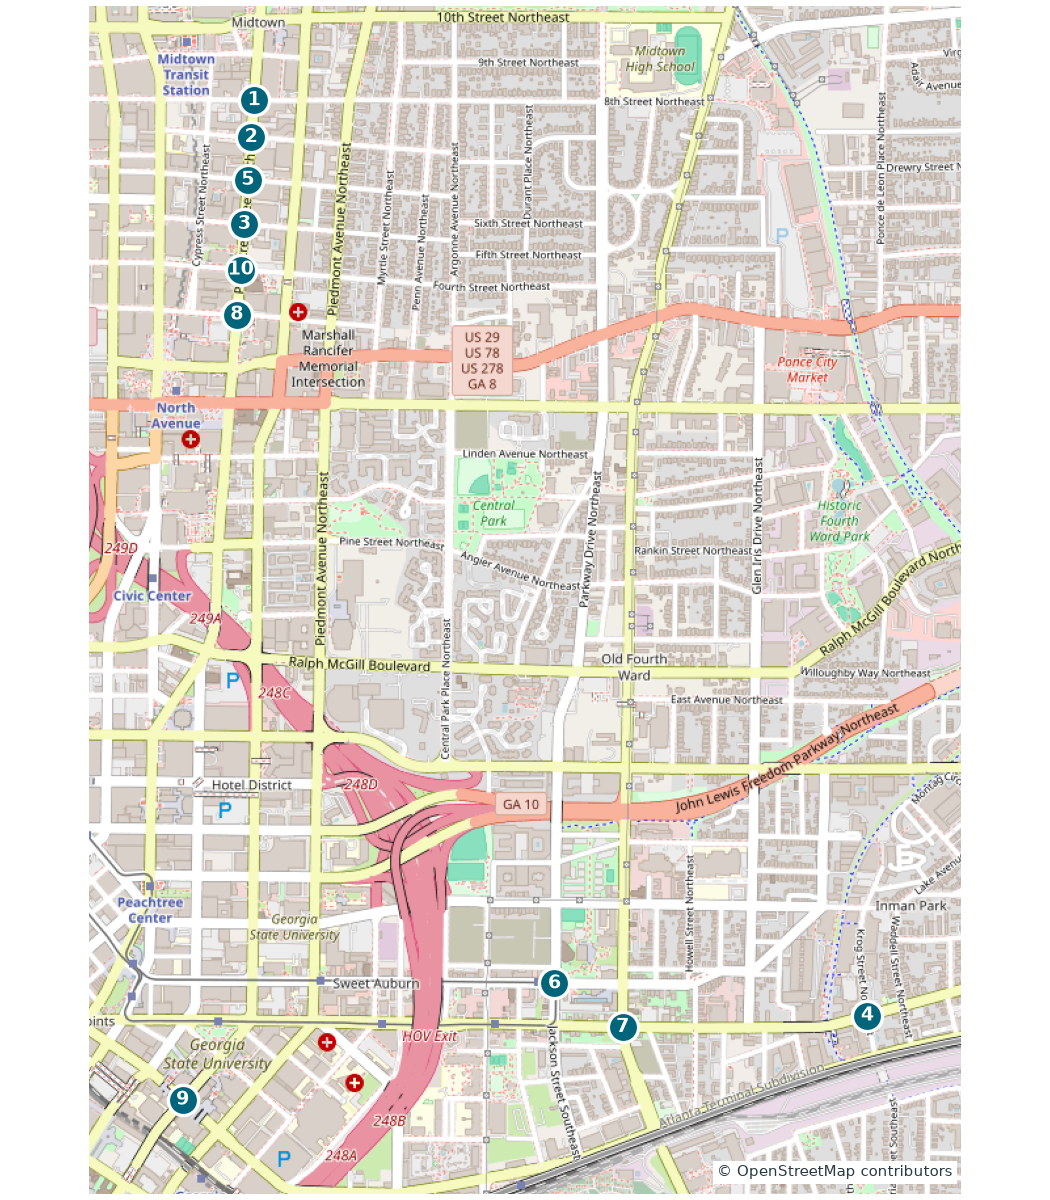

In [3]:
import matplotlib.pyplot as plt

map_sites = top_20.head(10)
# Project lon/lat to the tile grid used by the bundled OpenStreetMap map.
zoom = 15
lon = map_sites['longitude']
lat = np.deg2rad(map_sites['latitude'])
x = (lon + 180) / 360 * 2**zoom
y = (1 - np.arcsinh(np.tan(lat)) / np.pi) / 2 * 2**zoom

fig, ax = plt.subplots(figsize=(7, 8), layout='constrained')
background = plt.imread(root / 'notebooks/phase1/atlanta_osm_basemap.png')
ax.imshow(background, extent=(8702, 8706, 13118, 13113))
ax.scatter(x, y, s=210, color='#00657a', edgecolor='white', linewidth=1.6, zorder=3)
for rank, marker_x, marker_y in zip(map_sites.index, x, y):
    ax.text(marker_x, marker_y, str(rank), ha='center', va='center',
            color='white', weight='bold', fontsize=9, zorder=4)
ax.set(xlim=(x.min() - .28, x.max() + .28), ylim=(y.max() + .28, y.min() - .28))
ax.set_axis_off()
ax.text(.99, .012, '© OpenStreetMap contributors', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7, color='#283a42',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})
plt.show()

## Candidate Arrival Lines

Each column counts the OpenStreetMap road junctions, ramps, and driveway connections between the intersection center and the candidate line along the approach. **0** means no mapped access point. **—** means the approach could not be traced reliably to that distance.

In [ ]:
counts = pd.read_csv(root / 'notebooks/phase1/approach_access_counts.csv')
table = analysis_sites.reset_index()[['Rank', 'osm_node', 'intersection']].merge(
    counts.drop(columns='rank'), on='osm_node', validate='one_to_many'
)
distances = ['200 m', '150 m', '100 m', '50 m']
table[distances] = table[distances].astype('Int64')
table = table[['Rank', 'intersection', 'approach', *distances]].sort_values(['Rank', 'approach'])
display(table.style.format(na_rep='—').hide(axis='index'))

Rank,intersection,approach,200 m,150 m,100 m,50 m
1,Peachtree Ave × 8Th St,East · 8th Street Northeast,3,3,2,0
1,Peachtree Ave × 8Th St,North · Peachtree Street Northeast,3,3,1,0
1,Peachtree Ave × 8Th St,South · Peachtree Street Northeast,2,2,1,0
1,Peachtree Ave × 8Th St,West · 8th Street Northeast,5,4,3,1
3,5Th St × Peachtree St,East · Fifth Street Northeast,3,3,2,0
3,5Th St × Peachtree St,North · Peachtree Street Northeast,4,3,2,0
3,5Th St × Peachtree St,South · Peachtree Street Northeast,2,1,0,0
3,5Th St × Peachtree St,West · Fifth Street Northeast,4,3,1,1
4,Edgewood Ave × Krog St,East · Edgewood Avenue Northeast,4,2,1,1
4,Edgewood Ave × Krog St,North · Krog Street Northeast,4,4,2,1


## Observed Inbound and Outbound Crossings at 50 m

Count Point Report crossings at the same line in both directions for each of the four arms. The lines are perpendicular to the mapped road centerline, 50 m along the road from the intersection center. Each crossing is inferred from successive nearby points of the same vehicle and trip. These are observed crossing events, including repeat visits, and the inbound and outbound bars do not establish turning movements.

The screening uses snapped coordinates, a line extending 8 m on either side of the centerline, and a maximum time gap of 10 s between observations. These are provisional screening settings. The chart title states how many Point Report shards were scanned. By default, all Point Report shards are scanned.

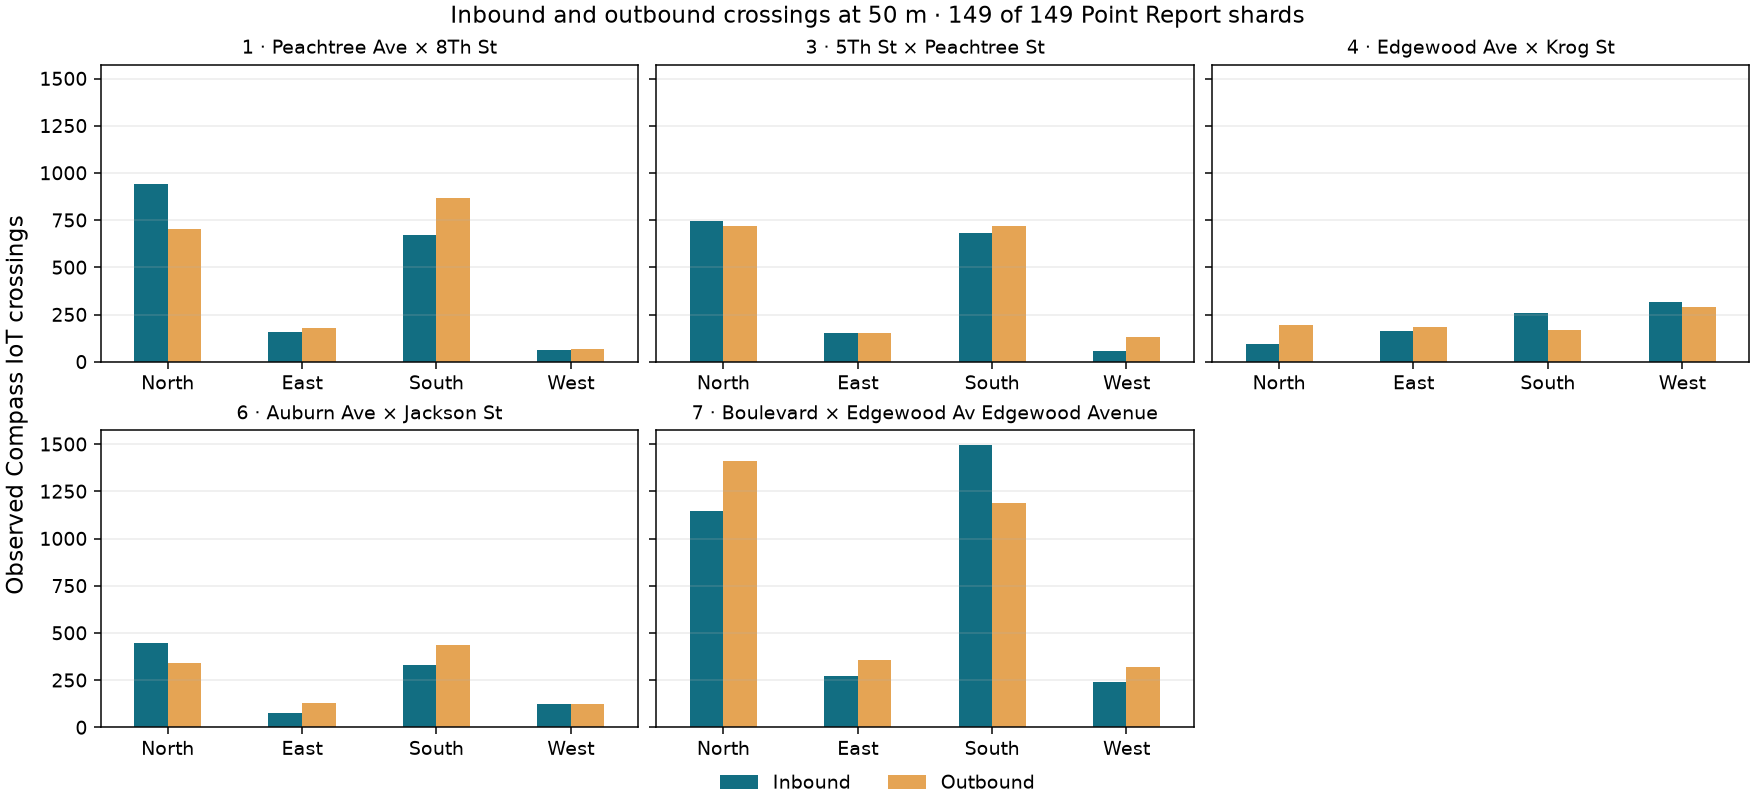

In [ ]:
MAX_CROSSING_FILES = None
HALF_WIDTH_M = 8
MAX_GAP_S = 10
lines = pd.read_csv(root / 'notebooks/phase1/arrival_lines_50m.csv')
lines = lines.loc[lines['osm_node'].isin(analysis_sites['osm_node'])]
files = point_files[:MAX_CROSSING_FILES]
keys = ['VehicleID', 'TripID']
coordinates = ['SnappedLongitude', 'SnappedLatitude']
time = 'Timestamp_UTC'
nearby = []
for file in files:
    for chunk in pd.read_csv(file, usecols=[*keys, time, *coordinates],
                             dtype=dict.fromkeys(keys, str), chunksize=250_000):
        chunk['x'] = chunk[coordinates[0]] * 92_300
        chunk['y'] = chunk[coordinates[1]] * 111_000
        keep = np.zeros(len(chunk), dtype=bool)
        for line in lines.itertuples(index=False):
            keep |= (abs(chunk['x'] - line.x_m) <= 110) & (abs(chunk['y'] - line.y_m) <= 110)
        nearby.append(chunk.loc[keep, [*keys, time, 'x', 'y']])

points = pd.concat(nearby, ignore_index=True).dropna()
points[time] = pd.to_datetime(points[time], format='mixed', utc=True, errors='coerce')
points = points.dropna().drop_duplicates().sort_values([*keys, time]).reset_index(drop=True)
previous = points.groupby(keys, sort=False)[[time, 'x', 'y']].shift()
gap = (points[time] - previous[time]).dt.total_seconds()
valid_pair = gap.gt(0) & gap.le(MAX_GAP_S)

records = []
event_frames = []
for line in lines.itertuples(index=False):
    dx, dy = points['x'] - line.x_m, points['y'] - line.y_m
    before_x, before_y = previous['x'] - line.x_m, previous['y'] - line.y_m
    after = dx * line.outward_east + dy * line.outward_north
    before = before_x * line.outward_east + before_y * line.outward_north
    inbound = before.gt(0) & after.le(0)
    outbound = before.le(0) & after.gt(0)
    crossings = valid_pair & (inbound | outbound)
    fraction = before[crossings] / (before[crossings] - after[crossings])
    lateral_before = -before_x[crossings] * line.outward_north + before_y[crossings] * line.outward_east
    lateral_after = -dx[crossings] * line.outward_north + dy[crossings] * line.outward_east
    on_line = (lateral_before + fraction * (lateral_after - lateral_before)).abs().le(HALF_WIDTH_M)
    hits = on_line[on_line].index
    events = points.loc[hits, keys].copy()
    events['osm_node'] = line.osm_node
    events['approach'] = line.direction
    events['inbound'] = inbound.loc[hits]
    events['point_index'] = hits
    events['crossing_time_utc'] = previous.loc[hits, time] + (
        points.loc[hits, time] - previous.loc[hits, time]
    ) * fraction.loc[hits]
    event_frames.append(events)
    records.append({'osm_node': line.osm_node, 'approach': line.direction,
                    'Inbound': int((inbound[crossings] & on_line).sum()),
                    'Outbound': int((outbound[crossings] & on_line).sum())})

crossing_counts = pd.DataFrame(records)
crossing_events = pd.concat(event_frames, ignore_index=True)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True, layout='constrained')
for ax, (rank, site) in zip(axes.flat, analysis_sites.iterrows()):
    counts = crossing_counts.loc[crossing_counts['osm_node'].eq(site.osm_node)]
    counts.set_index('approach')[['Inbound', 'Outbound']].reindex(['North', 'East', 'South', 'West']).plot.bar(
        ax=ax, rot=0, legend=False, color=['#126e82', '#e5a454'])
    ax.set(title=f'{rank} · {site.intersection}', xlabel='')
    ax.title.set_fontsize(10)
    ax.grid(axis='y', alpha=.25)
axes.flat[-1].set_axis_off()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncols=2, frameon=False)
fig.supylabel('Observed Compass IoT crossings')
fig.suptitle(f'Inbound and outbound crossings at 50 m · {len(files)} of {len(point_files)} Point Report shards')
plt.show()

## Build Intersection Passage Records

Reuse the 50 m crossing events from the preceding cell. For each intersection and vehicle trip, list events in time order. Start one record at each inbound crossing. Link it to the next event only if it is outbound, the observations between the two crossings are continuous under the gap rule above, and at least one observed point is within 20 m of the mapped intersection center. The 20 m radius is a provisional check for an observed path through the intersection.

Estimate each crossing time by linear interpolation between the two GPS observations on either side of the line. Store the entry and exit arms, estimated crossing times in UTC, and the movement inferred from the two arms. Leave the exit and movement blank if the passage cannot be confirmed. A later inbound crossing on the same trip starts a separate record.

Use entry times for the **observed 50 m arrival profile**. Use confirmed passages for **turning proportions** and report how many inbound records could be matched. An unmatched entry may reflect missing observations or a vehicle leaving the approach before reaching the intersection.

In [ ]:
CENTER_RADIUS_M = 20
event_keys = ['osm_node', *keys]
events = crossing_events.sort_values([*event_keys, 'crossing_time_utc'])
next_event = events.groupby(event_keys, sort=False)[
    ['inbound', 'point_index', 'approach', 'crossing_time_utc']
].shift(-1)
centers = analysis_sites.set_index('osm_node')[['longitude', 'latitude']]
# Arms are ordered clockwise from north, using the side of the intersection.
arm_number = {arm: i for i, arm in enumerate(['North', 'East', 'South', 'West'])}
movements = ['U-turn', 'Left', 'Through', 'Right']

passage_rows = []
for index, entry in events.loc[events['inbound']].iterrows():
    exit_event = next_event.loc[index]
    exit_arm, exit_time, movement = None, pd.NaT, None
    if pd.notna(exit_event['inbound']) and not exit_event['inbound']:
        first, last = entry['point_index'], int(exit_event['point_index'])
        center = centers.loc[entry['osm_node']]
        path_points = points.loc[first:last - 1]
        near_center = (
            (path_points['x'] - center['longitude'] * 92_300)**2
            + (path_points['y'] - center['latitude'] * 111_000)**2
        ).le(CENTER_RADIUS_M**2).any()
        if last > first and valid_pair.loc[first + 1:last].all() and near_center:
            exit_arm = exit_event['approach']
            exit_time = exit_event['crossing_time_utc']
            movement = movements[(arm_number[exit_arm] - arm_number[entry['approach']]) % 4]
    passage_rows.append((*[entry[key] for key in event_keys],
                         entry['approach'], entry['crossing_time_utc'], exit_arm, exit_time, movement))

passage_columns = [*event_keys, 'entry_arm', 'entry_time_utc', 'exit_arm', 'exit_time_utc', 'movement']
passages = pd.DataFrame(passage_rows, columns=passage_columns)
print(f"Observed entries: {len(passages):,} | Matched passages: {passages['movement'].notna().sum():,}")
display(passages.head(10))

## Inspect One GPS Trip

Show the first matched passage as an example. The numbered points are snapped GPS observations in travel order. The diamonds mark the estimated entry and exit times, interpolated between consecutive observations at the 50 m lines. The dashed circle shows the intersection-center check. The table below is the single passage record produced from those points.

The saved example was generated using all 149 Point Report files.

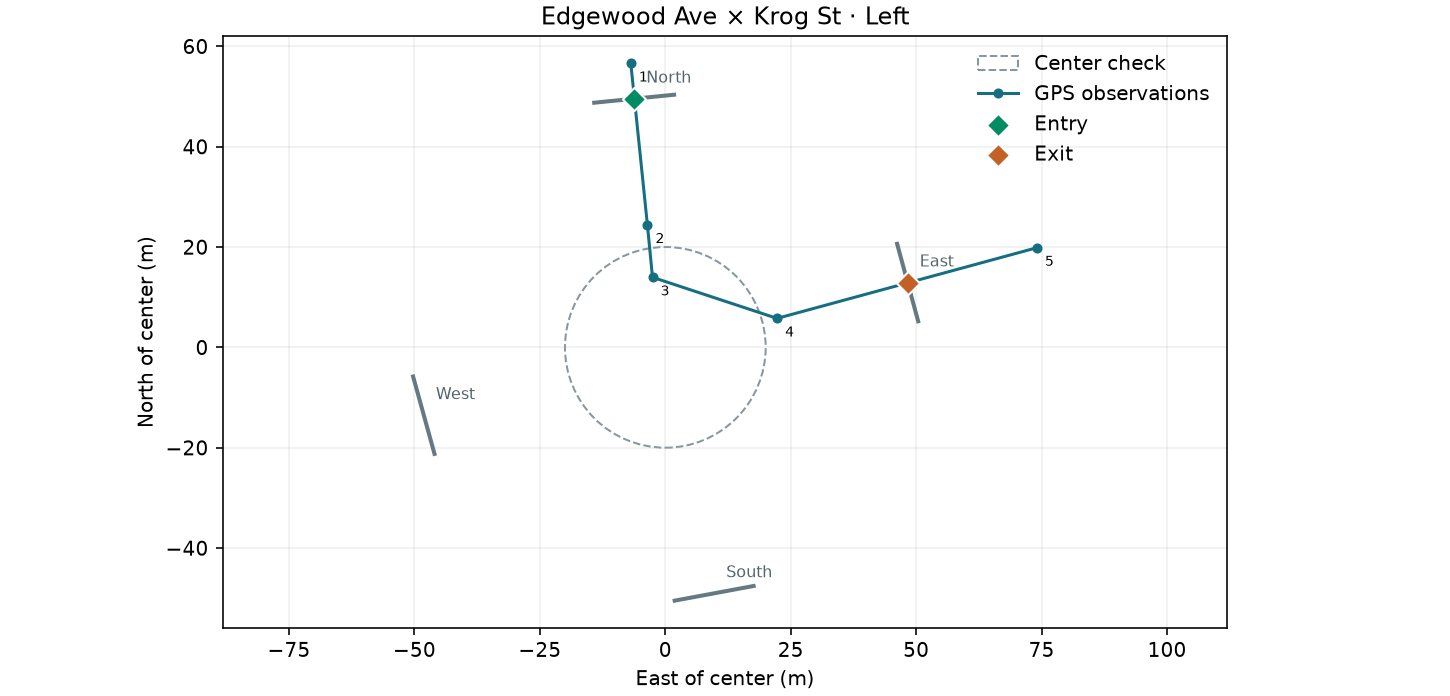

entry_arm,entry_time_utc,exit_arm,exit_time_utc,movement
North,2026-08-20 11:09:07.875354+00:00,East,2026-08-20 11:09:23.017219+00:00,Left


In [ ]:
matched = passages.loc[passages['movement'].notna()]
if matched.empty:
    print('No matched passage in the current selection of Point Report files.')
else:
    example = matched.iloc[0]
    same_trip = events[event_keys].eq(example[event_keys], axis='columns').all(axis=1)
    entry = events.loc[same_trip & events['inbound']
                       & events['crossing_time_utc'].eq(example['entry_time_utc'])].iloc[0]
    exit_event = next_event.loc[entry.name]
    trace = points.loc[entry['point_index'] - 1:int(exit_event['point_index'])]
    center = centers.loc[example['osm_node']]
    cx, cy = center['longitude'] * 92_300, center['latitude'] * 111_000
    site_lines = lines.loc[lines['osm_node'].eq(example['osm_node'])]

    from matplotlib.patches import Circle

    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    ax.add_patch(Circle((0, 0), CENTER_RADIUS_M, fill=False, linestyle='--',
                        edgecolor='#87979f', label='Center check'))
    for line in site_lines.itertuples(index=False):
        x, y = line.x_m - cx, line.y_m - cy
        ax.plot([x - HALF_WIDTH_M * line.outward_north, x + HALF_WIDTH_M * line.outward_north],
                [y + HALF_WIDTH_M * line.outward_east, y - HALF_WIDTH_M * line.outward_east],
                color='#657982', linewidth=2)
        ax.annotate(line.direction, (x, y), xytext=(6, 8), textcoords='offset points',
                    color='#52646c', fontsize=8)
    ax.plot(trace['x'] - cx, trace['y'] - cy, 'o-', color='#166e82', markersize=4,
            label='GPS observations', zorder=3)
    for number, point in enumerate(trace.itertuples(), 1):
        ax.annotate(str(number), (point.x - cx, point.y - cy),
                    xytext=(4, -9), textcoords='offset points', fontsize=7)
    for label, event, color in [('Entry', entry, '#008b63'), ('Exit', exit_event, '#c26026')]:
        index = int(event['point_index'])
        before, after = points.loc[index - 1], points.loc[index]
        share = (event['crossing_time_utc'] - before[time]) / (after[time] - before[time])
        x = before['x'] + share * (after['x'] - before['x']) - cx
        y = before['y'] + share * (after['y'] - before['y']) - cy
        ax.scatter(x, y, marker='D', s=66, color=color, edgecolor='white', zorder=4, label=label)
    site_name = analysis_sites.set_index('osm_node').loc[example['osm_node'], 'intersection']
    ax.set(title=f"{site_name} · {example['movement']}", xlabel='East of center (m)',
           ylabel='North of center (m)', aspect='equal')
    # Give the map a landscape extent while keeping meter scales equal.
    left, right = ax.get_xlim()
    bottom, top = ax.get_ylim()
    midpoint = (left + right) / 2
    half_width = max((right - left) / 2, (top - bottom) * .85)
    ax.set_xlim(midpoint - half_width, midpoint + half_width)
    ax.grid(alpha=.2)
    ax.legend(loc='best', frameon=False)
    plt.show()
    display(matched.loc[[example.name], ['entry_arm', 'entry_time_utc', 'exit_arm',
                                       'exit_time_utc', 'movement']])

## Morning Arrivals and Turning Proportions at Edgewood × Krog

Use the Atlanta local time of each estimated 50 m entry. Show one morning (06:00–12:00), choosing the date with the most observed entries and the earliest date in a tie. Count all observed entries in fixed one-hour windows and in six 10-minute bins per window. Highlight the one-hour window with the most observed entries, choosing the earliest window in a tie. Calculate left, through, and right shares by entry arm from matched passages in that window. The labels show the number of usable movements relative to all observed entries for each arm.

Counts describe the available Compass Point Report observations. A zero means no observed entry in that bin. These counts are not estimates of total traffic.

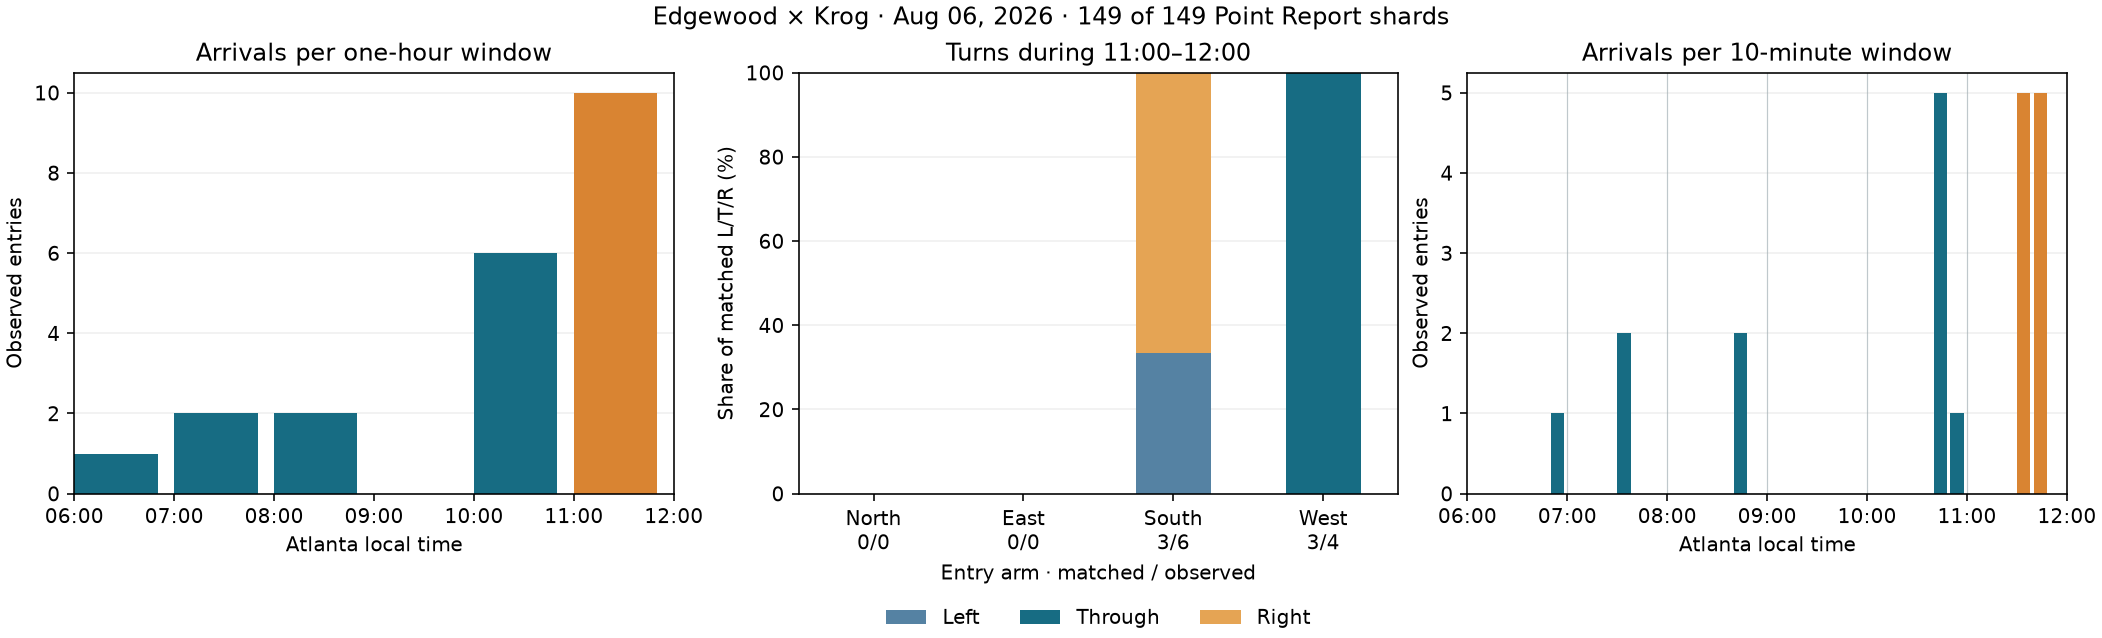

In [ ]:
import matplotlib.dates as mdates

edgewood = passages.loc[passages['osm_node'].eq(69214484)].copy()
edgewood['entry_local'] = edgewood['entry_time_utc'].dt.tz_convert('America/New_York')
morning = edgewood.loc[edgewood['entry_local'].dt.hour.between(6, 11)]
if morning.empty:
    print('No morning arrivals at Edgewood × Krog in the selected files.')
else:
    by_date = morning.groupby(morning['entry_local'].dt.normalize()).size().sort_index()
    date = by_date.idxmax()
    start = date + pd.Timedelta(hours=6)
    end = date + pd.Timedelta(hours=12)
    arrivals = morning.loc[morning['entry_local'].between(start, end, inclusive='left')]
    counts_10 = arrivals.groupby(arrivals['entry_local'].dt.floor('10min')).size().reindex(
        pd.date_range(start, end, freq='10min', inclusive='left'), fill_value=0)
    counts_hour = counts_10.resample('60min').sum()
    peak_start = counts_hour.idxmax()
    peak_end = peak_start + pd.Timedelta(hours=1)
    peak_arrivals = arrivals.loc[arrivals['entry_local'].between(peak_start, peak_end, inclusive='left')]
    approaches = ['North', 'East', 'South', 'West']
    turns = ['Left', 'Through', 'Right']
    turn_counts = pd.crosstab(peak_arrivals['entry_arm'], peak_arrivals['movement']).reindex(
        index=approaches, columns=turns, fill_value=0)
    matched_counts = turn_counts.sum(axis=1)
    turn_shares = turn_counts.div(matched_counts.replace(0, np.nan), axis=0) * 100
    entry_counts = peak_arrivals['entry_arm'].value_counts().reindex(approaches, fill_value=0)

    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4), layout='constrained')
    blue, highlight = '#176c83', '#d98432'
    axes[0].bar(counts_hour.index, counts_hour, width=50 / 1440, align='edge',
                color=[highlight if t == peak_start else blue for t in counts_hour.index])
    axes[0].set(title='Arrivals per one-hour window', ylabel='Observed entries')

    turn_shares.plot.bar(stacked=True, ax=axes[1], rot=0,
                         color=['#5582a3', '#176c83', '#e5a454'])
    axes[1].set(title=f'Turns during {peak_start:%H:%M}–{peak_end:%H:%M}',
                ylabel='Share of matched L/T/R (%)', xlabel='Entry arm · matched / observed', ylim=(0, 100))
    axes[1].set_xticks(range(4), [f'{arm}\n{matched_counts[arm]}/{entry_counts[arm]}' for arm in approaches])
    axes[1].legend(loc='upper center', bbox_to_anchor=(.5, -.23), ncols=3, frameon=False)
    if not matched_counts.any():
        axes[1].text(.5, .5, 'No matched L/T/R movements', transform=axes[1].transAxes,
                     ha='center', va='center')

    axes[2].bar(counts_10.index, counts_10, width=8 / 1440, align='edge',
                color=[highlight if peak_start <= t < peak_end else blue for t in counts_10.index])
    for boundary in counts_hour.index[1:]:
        axes[2].axvline(boundary, color='#bfc8cc', linewidth=.6, zorder=0)
    axes[2].set(title='Arrivals per 10-minute window', ylabel='Observed entries')
    for ax in [axes[0], axes[2]]:
        ax.set(xlim=(start, end), xlabel='Atlanta local time')
        ax.set_xticks(pd.date_range(start, end, freq='1h'))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=start.tz))
    for ax in axes:
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle(f'Edgewood × Krog · {date:%b %d, %Y} · {len(files)} of {len(point_files)} Point Report shards')
    plt.show()

## Convert One 30-Minute Window to Feature Shares

Use the Edgewood × Krog peak example above. Divide each 10-minute count by all observed entries in that one-hour window. For turning shares, divide each left, through, or right count by the total classified L/T/R passages on the same approach. The tables show each denominator and the percentage it produces.

In [ ]:
if morning.empty:
    print('No Edgewood × Krog morning window to illustrate.')
else:
    example_bins = counts_10.loc[(counts_10.index >= peak_start) & (counts_10.index < peak_end)]
    example_total = example_bins.sum()
    display(pd.DataFrame({
        '10-minute start': example_bins.index.strftime('%H:%M'),
        'Observed entries': example_bins.to_numpy(),
        'Share (%)': (100 * example_bins / example_total).round(1).to_numpy(),
    }))
    example_turns = turn_counts.add_suffix(' count')
    example_turns['Classified L/T/R'] = matched_counts
    display(example_turns.join(turn_shares.round(1).add_suffix(' share (%)')))

,10-minute start,Observed entries,Share (%)
0,11:00,0,0.0
1,11:10,0,0.0
2,11:20,0,0.0
3,11:30,5,50.0
4,11:40,5,50.0
5,11:50,0,0.0


movement,Left count,Through count,Right count,Classified L/T/R,Left share (%),Through share (%),Right share (%)
entry_arm,,,,,,,
North,0,0,0,0,NaN,NaN,NaN
East,0,0,0,0,NaN,NaN,NaN
South,1,0,2,3,33.3,0.0,66.7
West,0,3,0,3,0.0,100.0,0.0


## Distributions Across Observed One-Hour Windows

Show each selected intersection separately, using all observed local times. The axes and frequency colors use common scales across sites. Aggregate separately by site and date-time, and omit windows with zero observed entries. For each eligible hour, divide each of its six 10-minute counts by the hourly total. For each 10-minute position, a box plot summarizes its shares across all eligible hours at that site. Boxes span the 25th to 75th percentiles, with a median line and 1.5 IQR whiskers. Separate boxes show the spread at each position. The six shares from an individual hour sum to 100%.

Compute turning shares separately for each entry arm and one-hour window. Plot left and right shares together so the through share is preserved as 100% minus their sum.

The figures use at least five observed entries for arrival profiles or five classified L/T/R passages for turning profiles. These cutoffs are exploratory settings. The coverage table shows how many profiles remain after screening. Each arrival profile represents one window. In the turning plot, point size and color show how many approach-windows share the same composition.

,intersection,Arrival windows,Arrival windows plotted,Approach-windows with classified turns,Turning profiles plotted
0,Peachtree Ave × 8Th St,519,132,539,22
1,5Th St × Peachtree St,532,104,560,16
2,Edgewood Ave × Krog St,379,34,312,2
3,Auburn Ave × Jackson St,421,52,386,11
4,Boulevard × Edgewood Av Edgewood Avenue,599,275,858,89


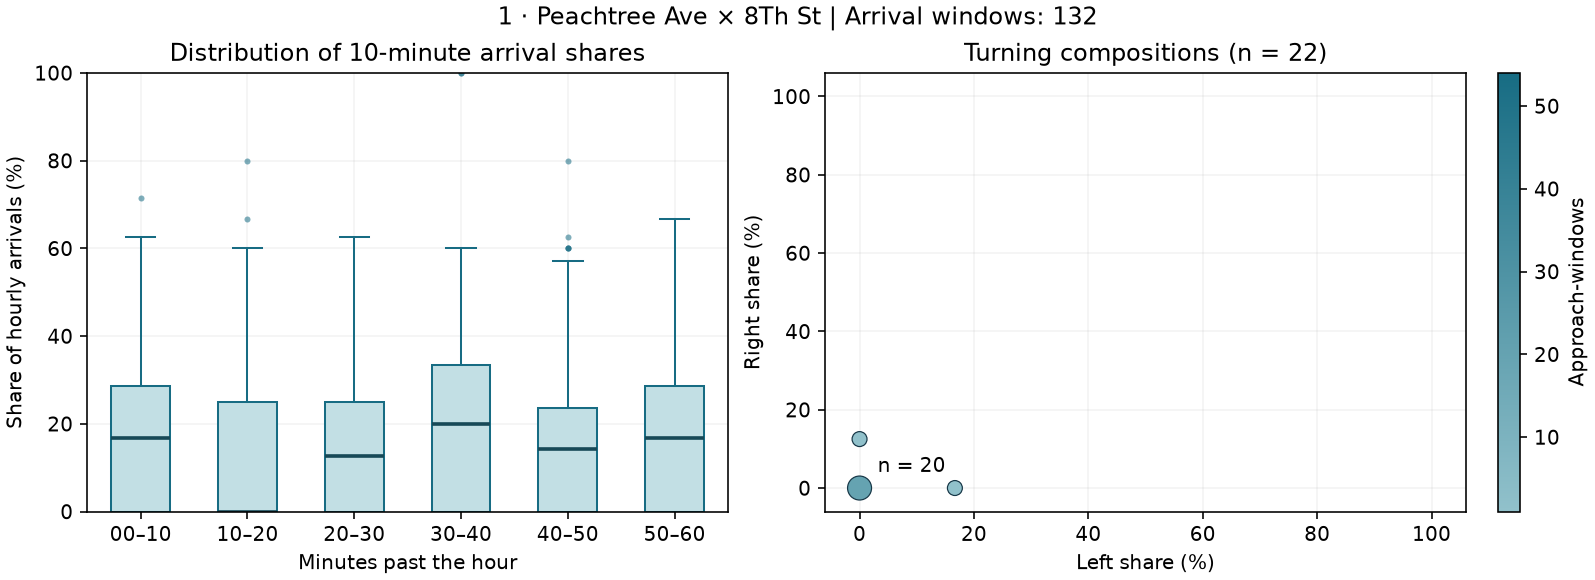

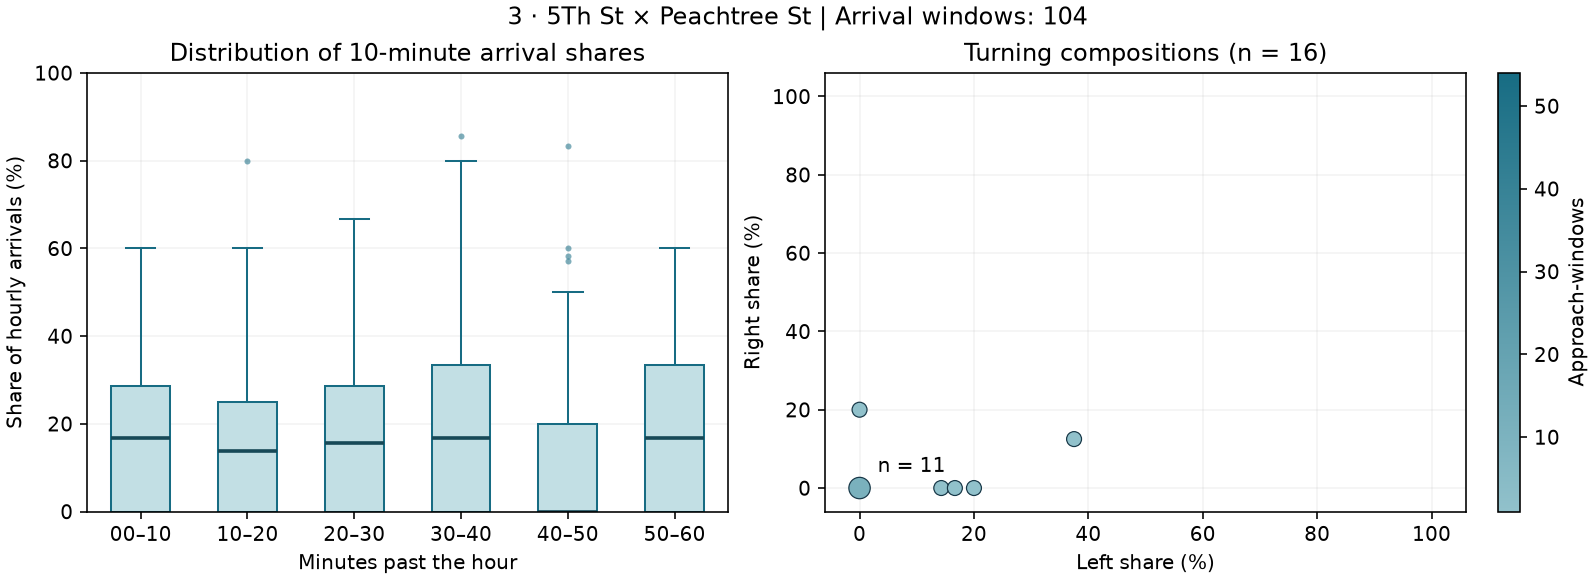

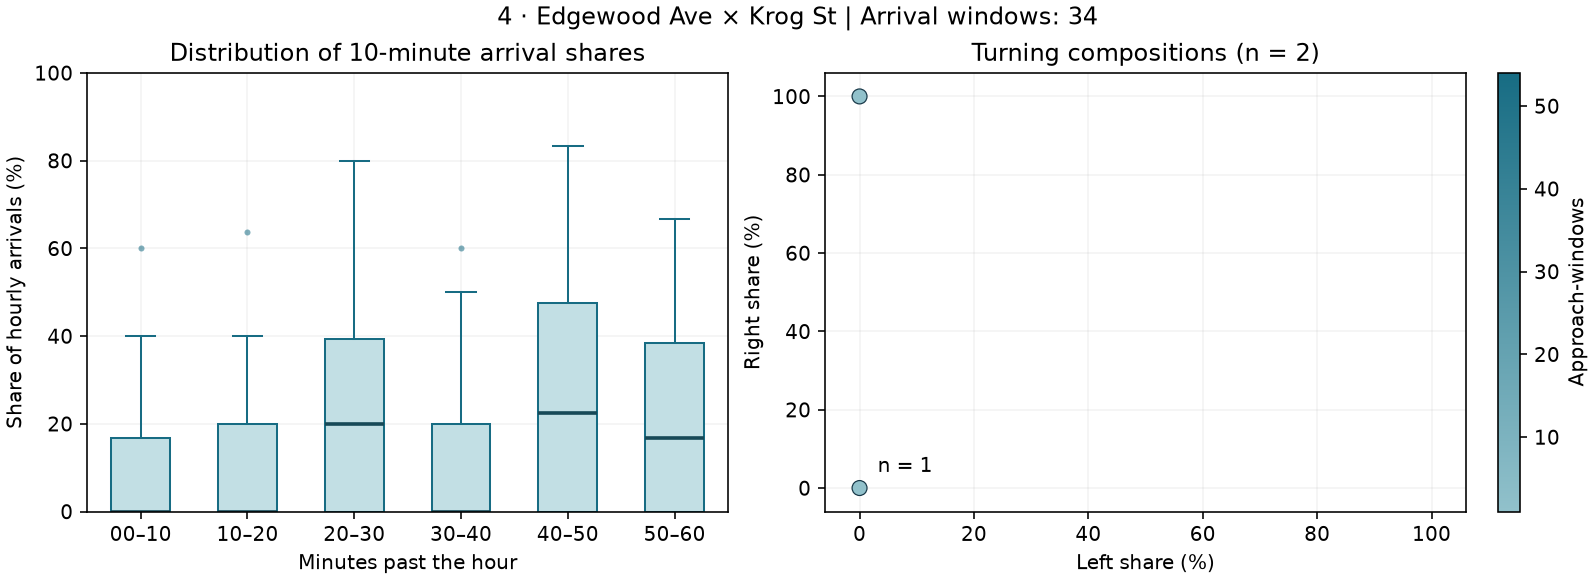

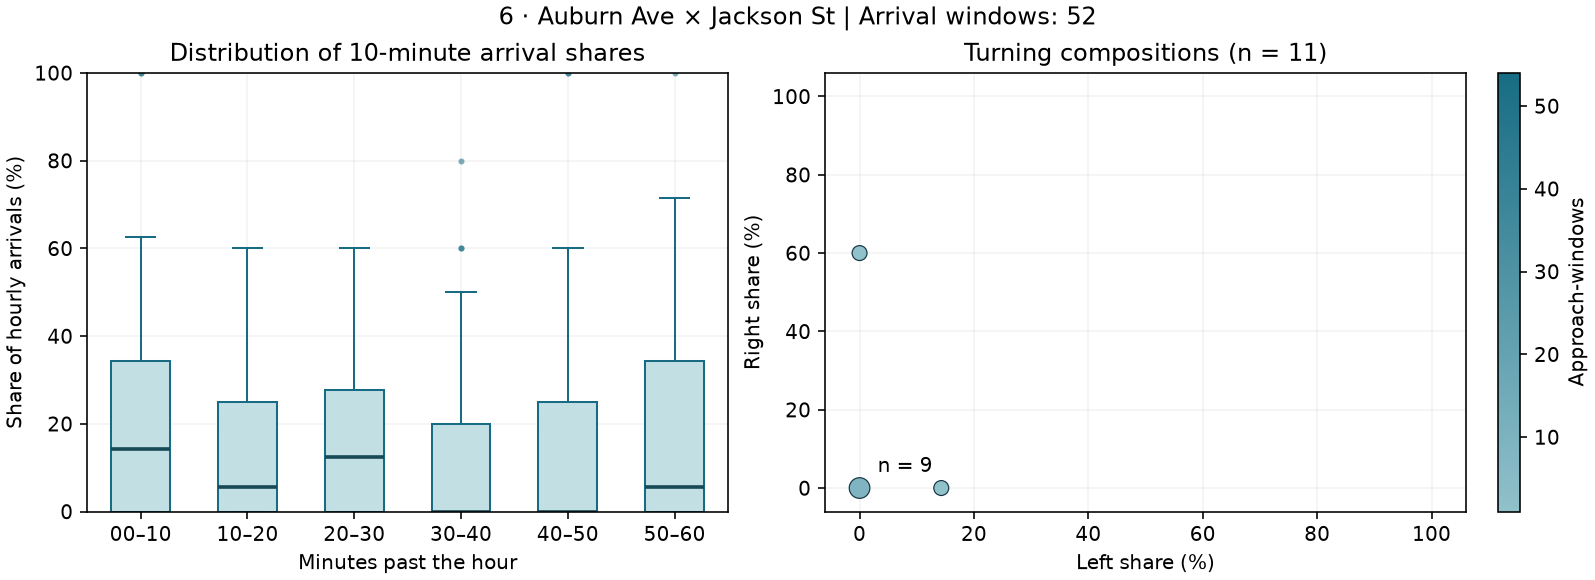

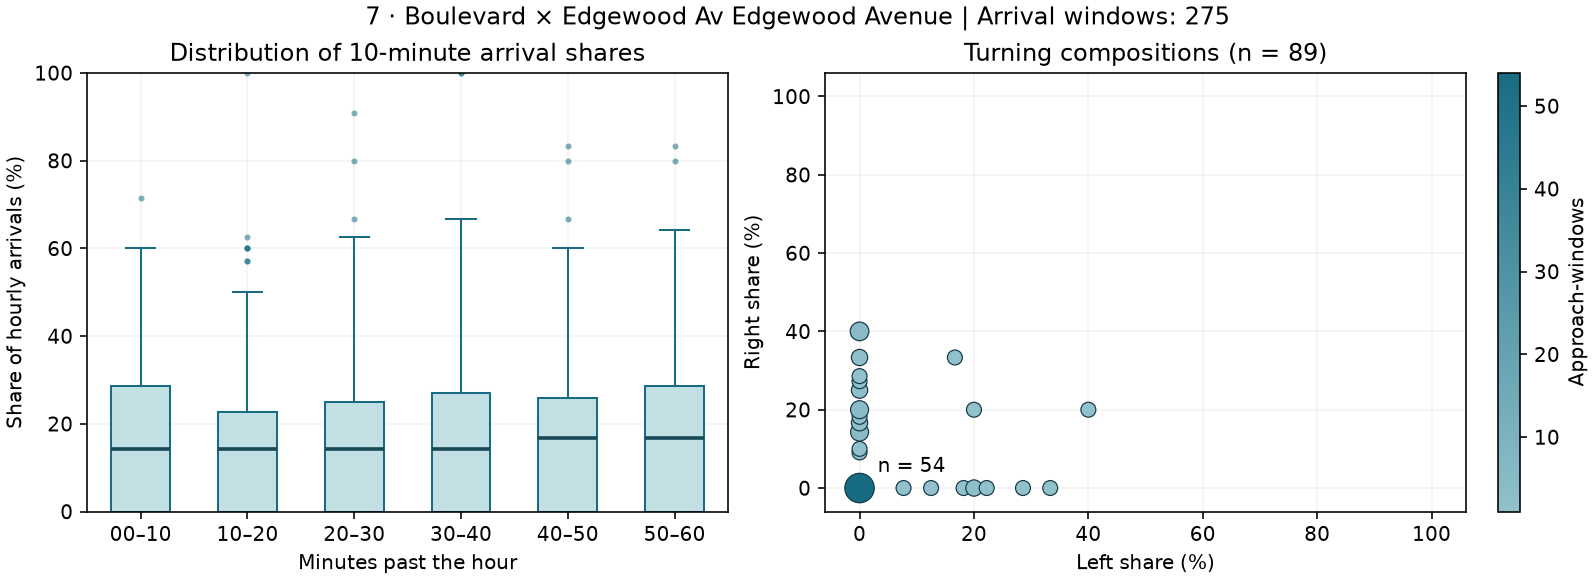

In [ ]:
MIN_ARRIVAL_ENTRIES = 5
MIN_CLASSIFIED_TURNS = 5

observations = passages.copy()
local_time = observations['entry_time_utc'].dt.tz_convert('America/New_York')
observations['window'] = local_time.dt.floor('60min')
observations['bin'] = local_time.dt.minute // 10 + 1
site_window = ['osm_node', 'window']

arrival_counts = observations.groupby([*site_window, 'bin']).size().unstack(fill_value=0)
arrival_counts = arrival_counts.reindex(columns=range(1, 7), fill_value=0)
arrival_totals = arrival_counts.sum(axis=1)
eligible_arrivals = arrival_counts.loc[arrival_totals.ge(MIN_ARRIVAL_ENTRIES)]
arrival_shares = eligible_arrivals.div(eligible_arrivals.sum(axis=1), axis=0) * 100
turns = ['Left', 'Through', 'Right']
classified = observations.loc[observations['movement'].isin(turns)]
movement_counts = classified.groupby([*site_window, 'entry_arm', 'movement']).size().unstack(fill_value=0)
movement_counts = movement_counts.reindex(columns=turns, fill_value=0)
turn_totals = movement_counts.sum(axis=1)
eligible_turns = movement_counts.loc[turn_totals.ge(MIN_CLASSIFIED_TURNS)]
movement_shares = eligible_turns.div(eligible_turns.sum(axis=1), axis=0) * 100

coverage = analysis_sites.set_index('osm_node')[['intersection']].copy()
for label, data in [
    ('Arrival windows', arrival_counts), ('Arrival windows plotted', arrival_shares),
    ('Approach-windows with classified turns', movement_counts),
    ('Turning profiles plotted', movement_shares),
]:
    coverage[label] = data.groupby(level='osm_node').size().reindex(coverage.index, fill_value=0)
display(coverage.reset_index(drop=True))

from matplotlib.colors import LinearSegmentedColormap

turn_cmap = LinearSegmentedColormap.from_list('turn_teal', ['#91c1cb', '#176c83'])
composition_counts = movement_shares.groupby(['osm_node', 'Left', 'Right']).size()
max_turn_count = max(2, composition_counts.max()) if not composition_counts.empty else 2

for rank, site in analysis_sites.iterrows():
    site_arrivals = arrival_shares.loc[arrival_shares.index.get_level_values('osm_node') == site.osm_node]
    site_turns = movement_shares.loc[movement_shares.index.get_level_values('osm_node') == site.osm_node]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    if site_arrivals.empty:
        axes[0].text(.5, .5, 'No windows meet the entry threshold', ha='center', va='center',
                     transform=axes[0].transAxes)
    else:
        axes[0].boxplot(
            [site_arrivals[bin_number].to_numpy() for bin_number in range(1, 7)],
            widths=.55, patch_artist=True,
            boxprops={'facecolor': '#c2dfe4', 'edgecolor': '#176c83'},
            medianprops={'color': '#174957', 'linewidth': 1.8},
            whiskerprops={'color': '#176c83'},
            capprops={'color': '#176c83'},
            flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': '#176c83',
                        'markeredgecolor': 'none', 'alpha': .55},
        )
    axes[0].set(title='Distribution of 10-minute arrival shares',
                xlabel='Minutes past the hour', ylabel='Share of hourly arrivals (%)',
                xlim=(.5, 6.5), ylim=(0, 100), xticks=range(1, 7),
                xticklabels=['00–10', '10–20', '20–30', '30–40', '40–50', '50–60'])
    compositions = site_turns.groupby(['Left', 'Right']).size().reset_index(name='windows')
    if not compositions.empty:
        bubbles = axes[1].scatter(compositions['Left'], compositions['Right'],
                                  s=30 + 25 * np.sqrt(compositions['windows']),
                                  c=compositions['windows'], cmap=turn_cmap, vmin=1, vmax=max_turn_count,
                                  edgecolor='#173747', linewidth=.6, zorder=3)
        fig.colorbar(bubbles, ax=axes[1], label='Approach-windows')
        most_common = compositions.loc[compositions['windows'].idxmax()]
        axes[1].annotate(f"n = {most_common['windows']:.0f}",
                         (most_common['Left'], most_common['Right']),
                         xytext=(9, 8), textcoords='offset points')
    else:
        axes[1].text(.5, .5, 'No windows meet the turn threshold', ha='center', va='center',
                     transform=axes[1].transAxes)
    axes[1].set(title=f'Turning compositions (n = {len(site_turns)})',
                xlabel='Left share (%)', ylabel='Right share (%)',
                xlim=(-6, 106), ylim=(-6, 106))
    for ax in axes:
        ax.grid(alpha=.15)
        ax.set_axisbelow(True)
    fig.suptitle(f'{rank} · {site.intersection} | Arrival windows: {len(site_arrivals)}')
    plt.show()

## Arrival Profiles by Local Clock Hour

Group eligible windows by intersection and local clock hour across dates. For example, the 08:00 curve connects the six median shares from all observed 08:00–09:00 windows at that intersection. Dots mark the six measured bin positions; the curve interpolates between them for readability. Legend counts give the number of hourly windows. The same five-entry threshold applies.

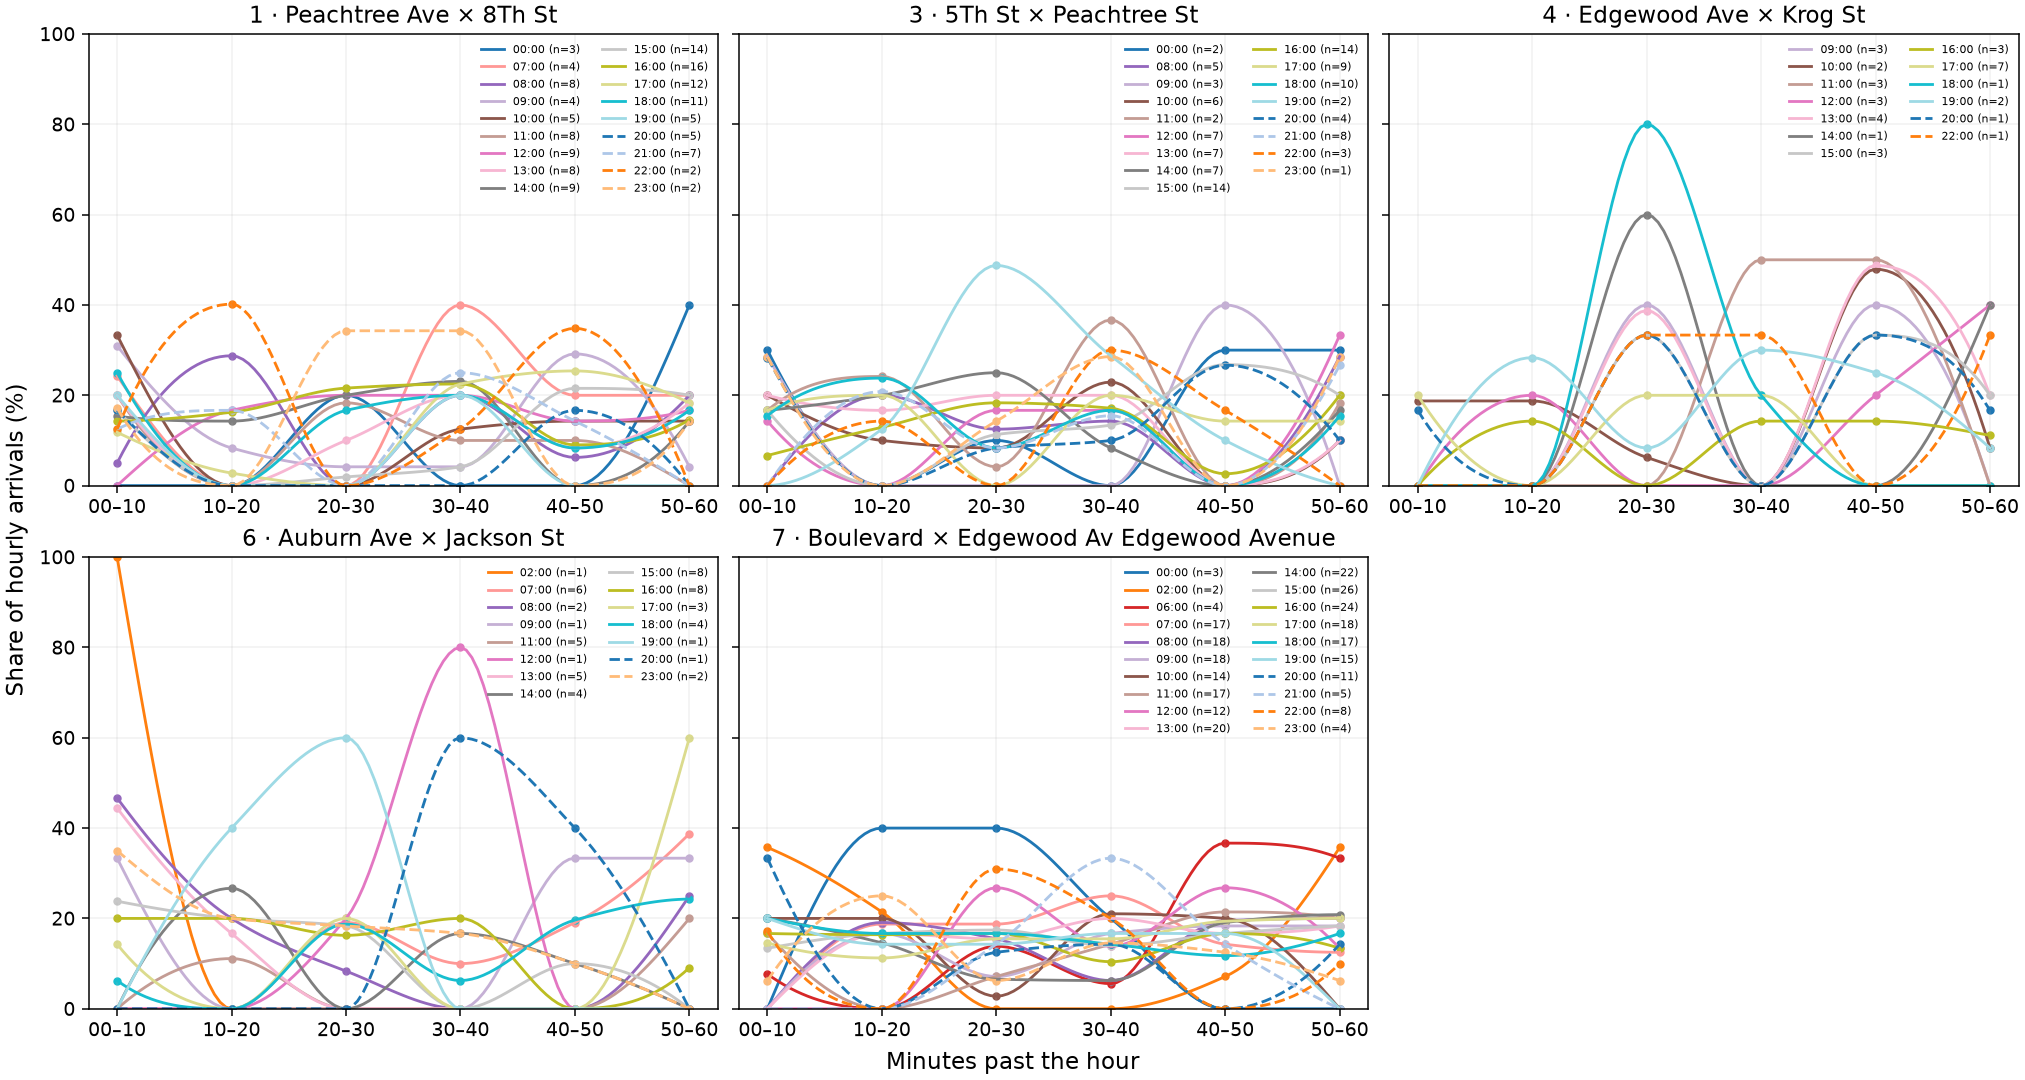

In [ ]:
from scipy.interpolate import PchipInterpolator

bin_positions = np.arange(1, 7)
smooth_positions = np.linspace(1, 6, 101)
bin_labels = ['00–10', '10–20', '20–30', '30–40', '40–50', '50–60']

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True, layout='constrained')
for ax, (rank, site) in zip(axes.flat, analysis_sites.iterrows()):
    site_profiles = arrival_shares.loc[arrival_shares.index.get_level_values('osm_node') == site.osm_node]
    clock_hours = site_profiles.index.get_level_values('window').hour
    for hour in sorted(clock_hours.unique()):
        hour_profiles = site_profiles.loc[clock_hours == hour]
        median = hour_profiles.median().to_numpy()
        color = plt.get_cmap('tab20')(hour % 20)
        ax.plot(smooth_positions, PchipInterpolator(bin_positions, median)(smooth_positions),
                color=color, linestyle='--' if hour >= 20 else '-',
                label=f'{hour:02d}:00 (n={len(hour_profiles)})')
        ax.scatter(bin_positions, median, s=12, color=color)
    if ax.lines:
        ax.legend(loc='upper right', frameon=False, fontsize=6, ncols=2)
    else:
        ax.text(.5, .5, 'No eligible hours', transform=ax.transAxes, ha='center', va='center')
    ax.set(title=f'{rank} · {site.intersection}',
           xticks=bin_positions, xticklabels=bin_labels, ylim=(0, 100))
    ax.grid(alpha=.18)
for ax in list(axes.flat)[len(analysis_sites):]:
    ax.set_axis_off()
for ax in list(axes.flat)[:len(analysis_sites)]:
    ax.tick_params(labelbottom=True)
fig.supxlabel('Minutes past the hour')
fig.supylabel('Share of hourly arrivals (%)')
plt.show()

## Arrival Profiles by Peak and Off-Peak Period

Summarize the six 10-minute shares by intersection and period using all eligible hours. The curve is the median and the shaded band covers the 25th–75th percentiles. The periods are provisional local-time definitions. AM peak is 07:00–09:00 and PM peak is 16:00–19:00. Other hours before noon are AM off-peak; other hours from noon onward are PM off-peak. These bands describe observed variation across hourly windows.

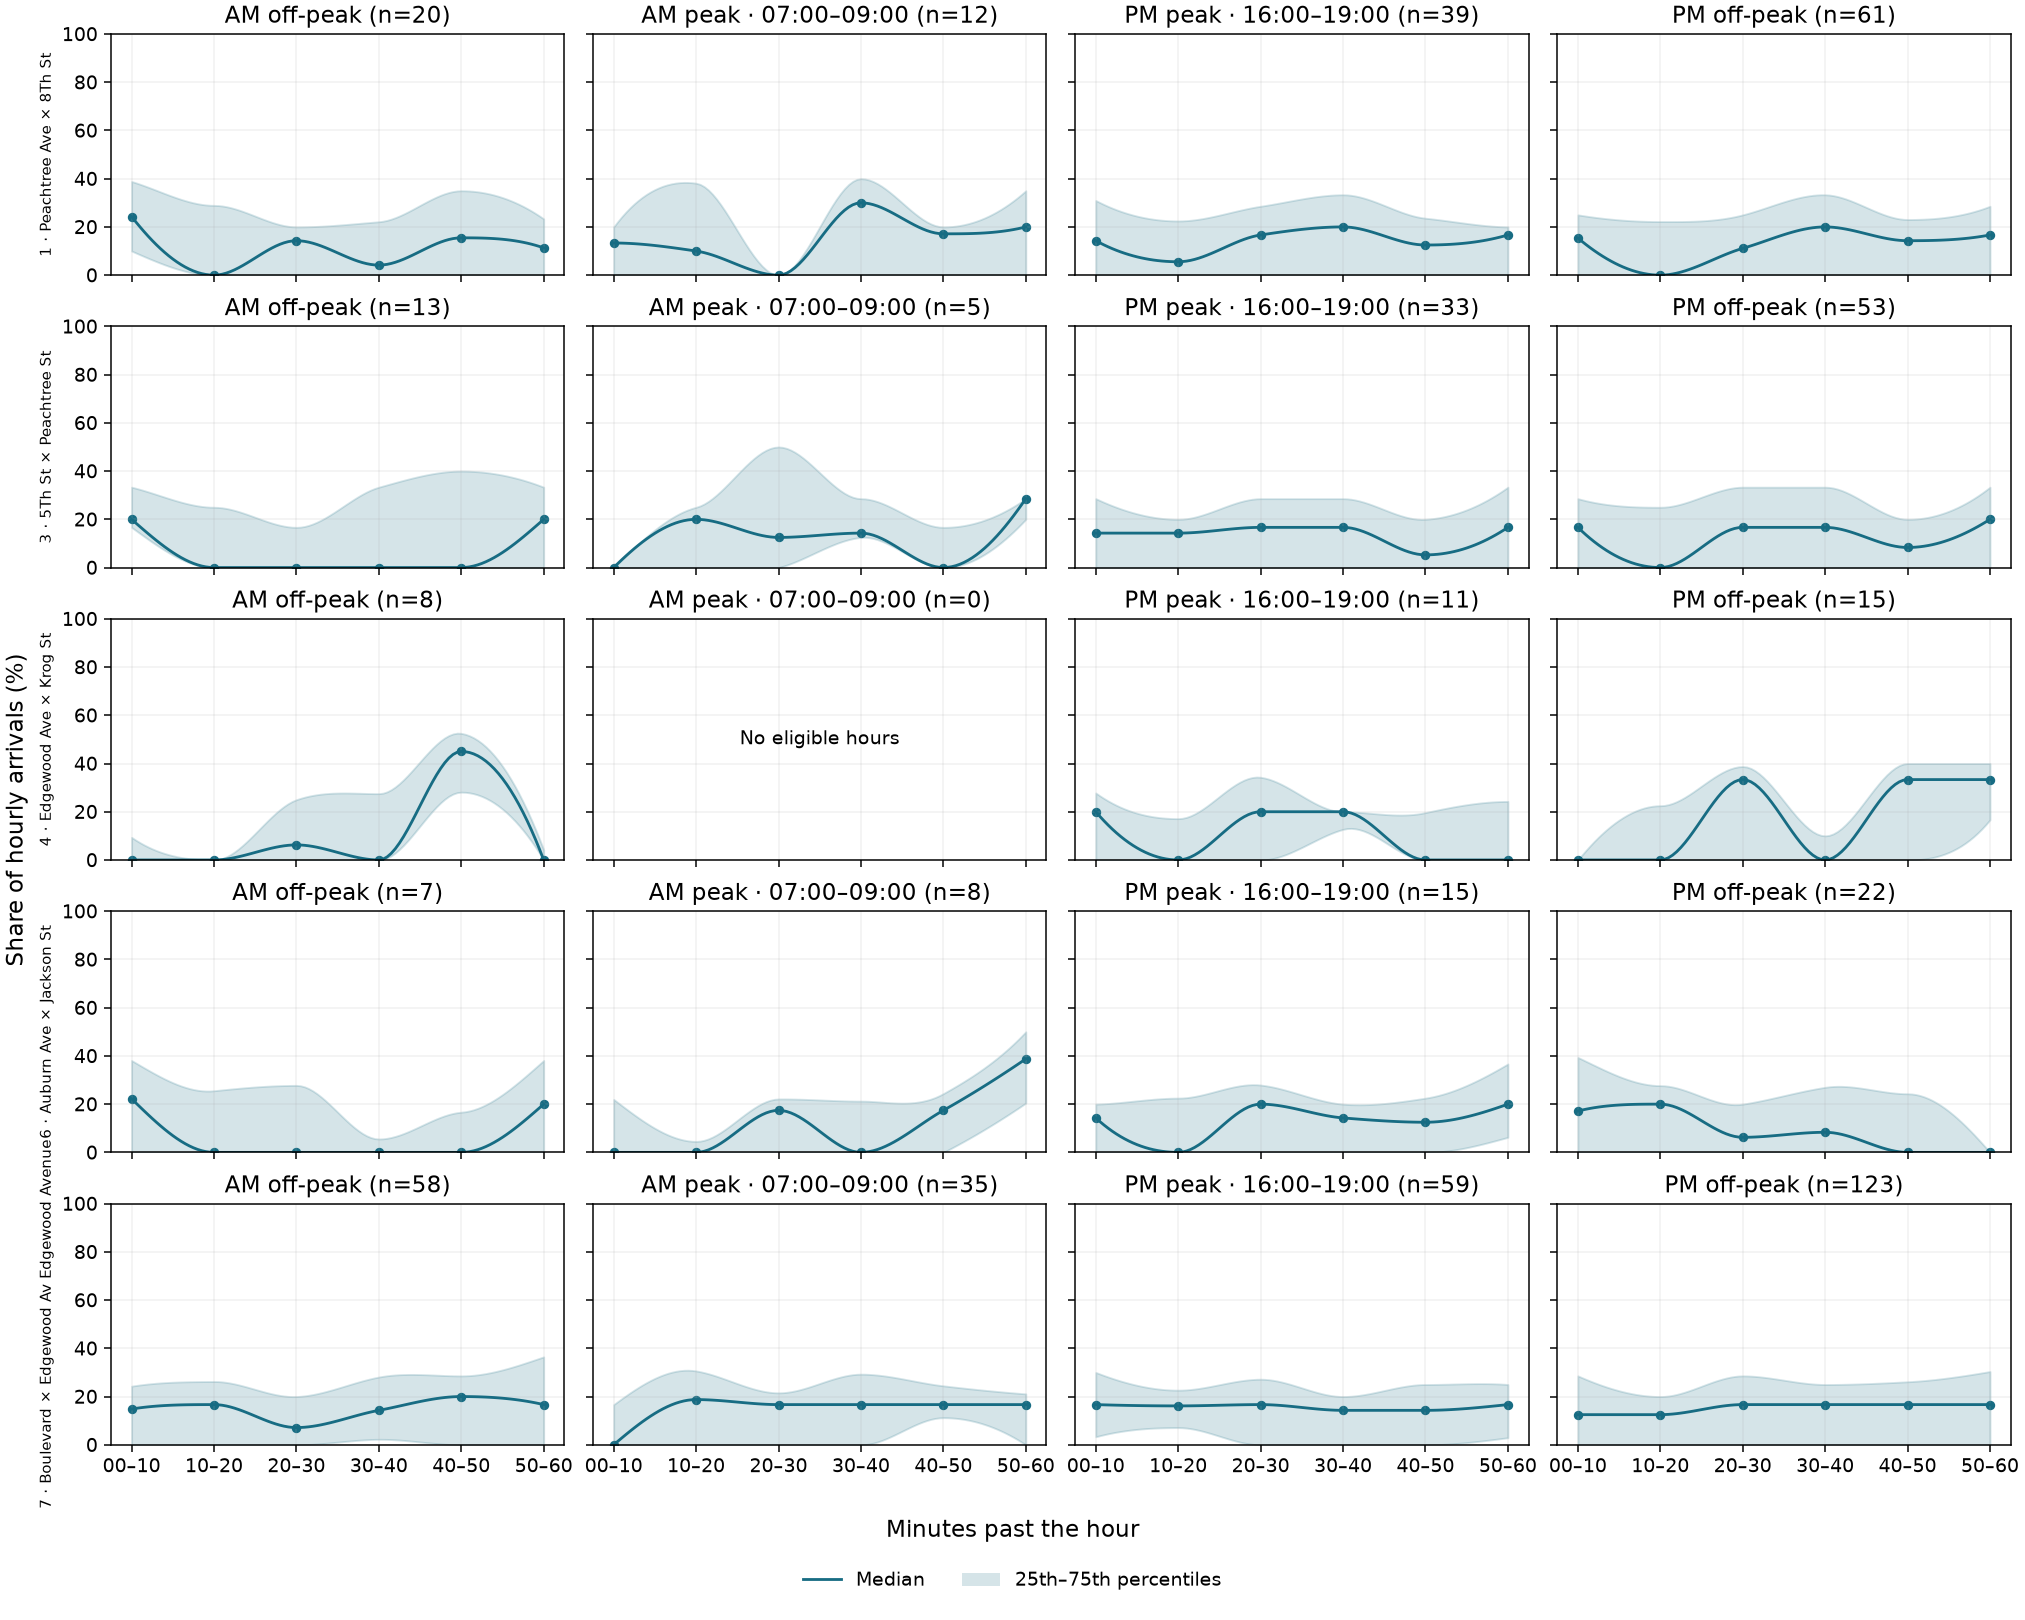

In [ ]:
periods = [
    ('AM off-peak', [0, 1, 2, 3, 4, 5, 6, 9, 10, 11]),
    ('AM peak · 07:00–09:00', [7, 8]),
    ('PM peak · 16:00–19:00', [16, 17, 18]),
    ('PM off-peak', [12, 13, 14, 15, 19, 20, 21, 22, 23]),
]

fig, axes = plt.subplots(len(analysis_sites), len(periods), figsize=(15, 12),
                         sharex=True, sharey=True, layout='constrained')
for row, (rank, site) in zip(axes, analysis_sites.iterrows()):
    site_profiles = arrival_shares.loc[arrival_shares.index.get_level_values('osm_node') == site.osm_node]
    clock_hours = site_profiles.index.get_level_values('window').hour
    for (label, hours), ax in zip(periods, row):
        profile = site_profiles.loc[clock_hours.isin(hours)]
        if profile.empty:
            ax.text(.5, .5, 'No eligible hours', transform=ax.transAxes, ha='center', va='center')
        else:
            low, median, high = profile.quantile([.25, .5, .75]).to_numpy()
            # Interpolate the width around the median so the band stays ordered.
            middle = PchipInterpolator(bin_positions, median)(smooth_positions)
            lower = middle - PchipInterpolator(bin_positions, median - low)(smooth_positions)
            upper = middle + PchipInterpolator(bin_positions, high - median)(smooth_positions)
            ax.fill_between(smooth_positions, lower.clip(0, 100), upper.clip(0, 100),
                            color='#176c83', alpha=.18, label='25th–75th percentiles')
            ax.plot(smooth_positions, middle, color='#176c83', label='Median')
            ax.scatter(bin_positions, median, s=16, color='#176c83')
        ax.set(title=f'{label} (n={len(profile)})', ylim=(0, 100),
               xticks=bin_positions, xticklabels=bin_labels)
        ax.grid(alpha=.18)
    row[0].set_ylabel(f'{rank} · {site.intersection}', fontsize=8)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig.legend(handles=[Line2D([], [], color='#176c83', label='Median'),
                    Patch(facecolor='#176c83', alpha=.18, label='25th–75th percentiles')],
           loc='lower center', bbox_to_anchor=(.5, .008), ncols=2, frameon=False)
# Reserve separate rows below the panels for the x-axis title and legend.
fig.get_layout_engine().set(rect=(0, .085, 1, .915))
fig.supxlabel('Minutes past the hour', y=.048)
fig.supylabel('Share of hourly arrivals (%)')
plt.show()

## Turning Proportions Across Intersections

Each panel shows turning compositions for one intersection. Through share is 100% minus the left and right shares. A bubble combines approach-hours with the same composition; size and color indicate their count. Only approach-hours with at least five classified left, through, or right movements are included.

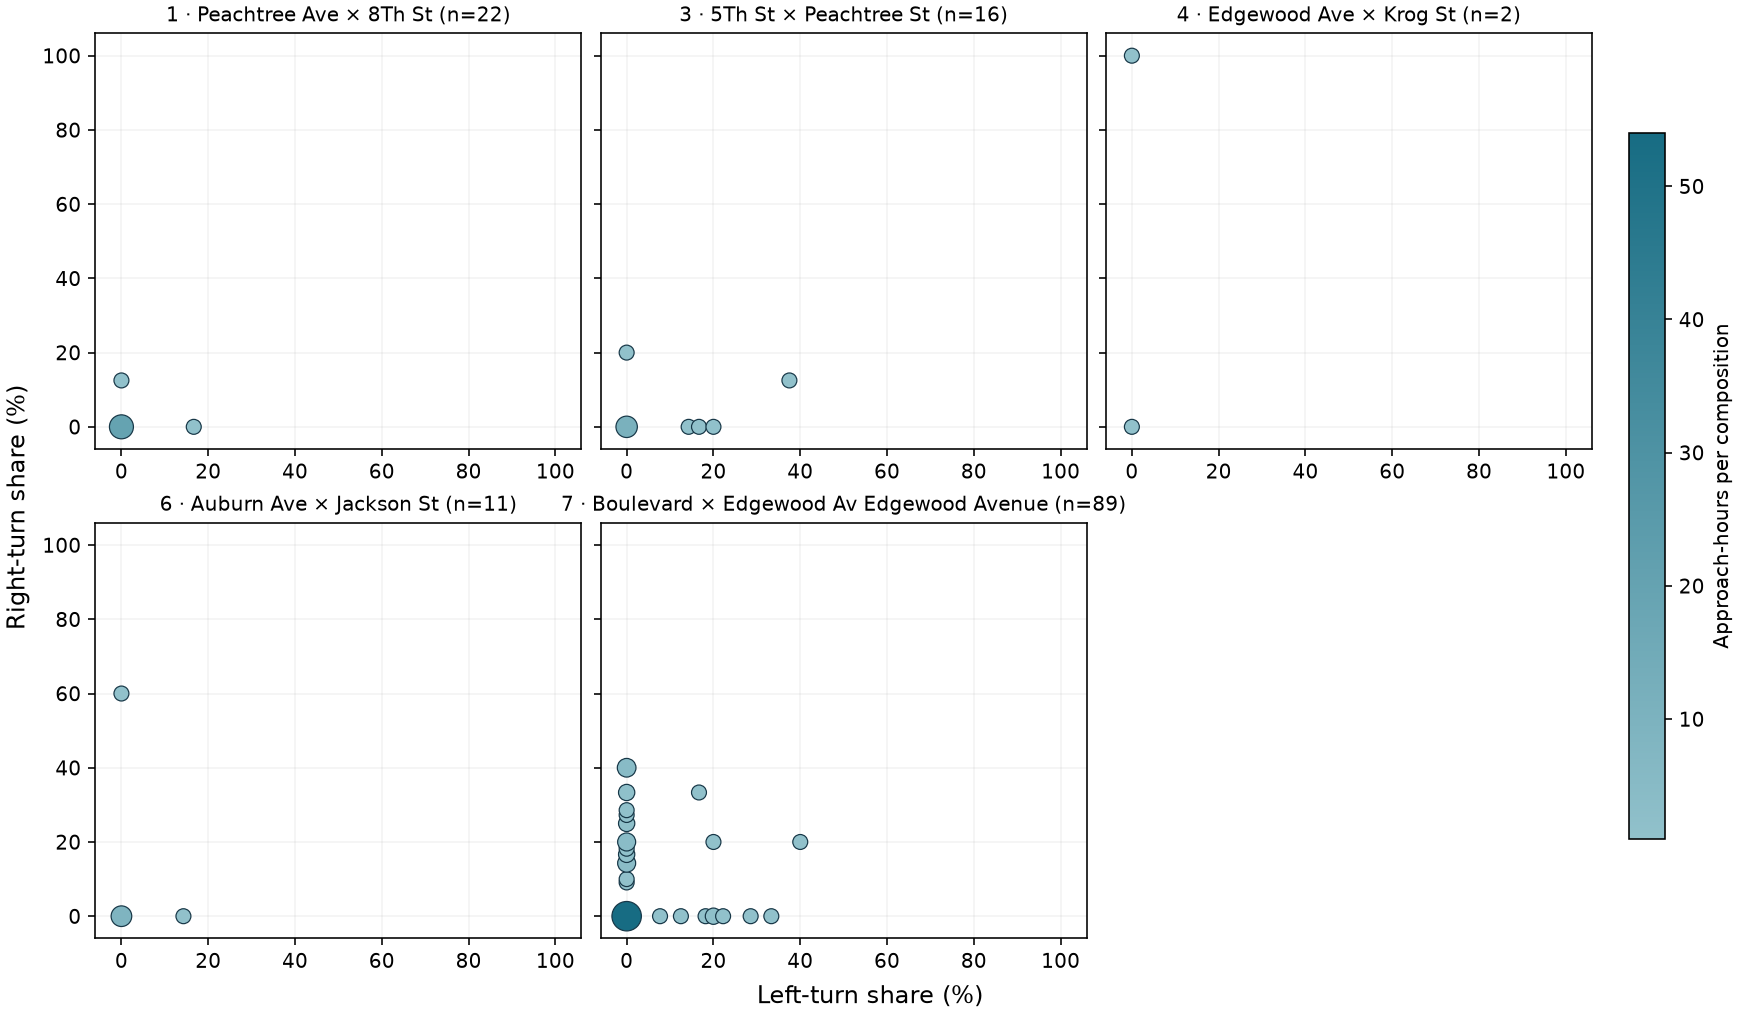

In [ ]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

turn_cmap = LinearSegmentedColormap.from_list('turn_teal', ['#91c1cb', '#176c83'])
compositions = movement_shares.groupby(['osm_node', 'Left', 'Right']).size().reset_index(name='windows')
maximum = int(compositions['windows'].max()) if not compositions.empty else 1
color_scale = Normalize(vmin=1, vmax=max(2, maximum))

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, layout='constrained')
active_axes = []
for ax, (rank, site) in zip(axes.flat, analysis_sites.iterrows()):
    active_axes.append(ax)
    site_compositions = compositions.loc[compositions['osm_node'].eq(site.osm_node)]
    sample_size = site_compositions['windows'].sum()
    if site_compositions.empty:
        ax.text(.5, .5, 'No eligible approach-hours', transform=ax.transAxes,
                ha='center', va='center')
    else:
        ax.scatter(site_compositions['Left'], site_compositions['Right'],
                   s=30 + 25 * np.sqrt(site_compositions['windows']), c=site_compositions['windows'],
                   cmap=turn_cmap, norm=color_scale, edgecolor='#173747', linewidth=.6, zorder=3)
    ax.set(title=f'{rank} · {site.intersection} (n={sample_size})',
           xlim=(-6, 106), ylim=(-6, 106), xticks=range(0, 101, 20), yticks=range(0, 101, 20))
    ax.title.set_fontsize(10)
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=.15)
    ax.set_axisbelow(True)
for ax in list(axes.flat)[len(active_axes):]:
    ax.set_axis_off()

if not compositions.empty:
    fig.colorbar(plt.cm.ScalarMappable(norm=color_scale, cmap=turn_cmap), ax=active_axes,
                 label='Approach-hours per composition', shrink=.78, pad=.025)
fig.supxlabel('Left-turn share (%)')
fig.supylabel('Right-turn share (%)')
plt.show()